# Modelo de anomalías del Observatorio Canguro

Este es el modelo que planteamos en la sección 10 de `informe_analisis_datos.ipynb`, entrenado y validado con la base de la Fundación. La idea en una línea: **una anomalía es un dato que está lejos de lo que esperamos para ese caso**, y lo esperado lo aprende el modelo de los mismos datos.

| Capa | Pregunta | Cómo |
|---|---|---|
| **0. Contrato** | ¿El dato cumple el esquema? | Tipo, variable conocida, fecha posible. Si no cumple se rechaza: no es una anomalía |
| **1. Valor** | ¿El valor tiene sentido por sí solo? | Mediana y MAD, códigos especiales, errores de unidad |
| **2. Contexto** | ¿Tiene sentido para este niño? | Un LightGBM por variable que da el rango esperado, calibrado con predicción conformal |
| **3. Trayectoria** | ¿Tiene sentido con su historia? | Ventanas de cada etapa, cambio entre visitas frente a pares, reglas como "la talla no baja" |
| **4. Grupo y tiempo** | ¿Algo empezó a medirse distinto? | Residuos, datos faltantes y redondeo por grupo y trimestre, contra su propio pasado |

**Lo que el modelo no usa.** El 15 de octubre de 2026 la Fundación restringió la fecha exacta de nacimiento, la sede, la llave del paciente y las fechas de hospitalización (`consumo.variable_restringida`); después volvió a habilitar todo salvo la llave, que nunca se usa. El modelo sigue trabajando sin sede ni fecha exacta de nacimiento, y no las reconstruye: cada dato lleva la edad que anotó el formulario, la división es por año de nacimiento, las estancias salen de sus duraciones y todo el programa es un solo grupo. Volver a usar la sede y la fecha de parto es una de las decisiones abiertas del proyecto.

**Entrada SEVARTI.** El modelo no sabe nada de KMC: recibe seis tablas (esquema, etapas, sujetos, mediciones en formato largo, episodios y quiebres conocidos) y todo lo decide el esquema. Si los expertos agregan una variable, es una fila más en el esquema. Aquí el adaptador `sevarti/kmc.py` hace de app: convierte la base a SEVARTI.

**Qué es este notebook.** El informe de validación: entrena con el pasado, mide con lo más reciente y muestra qué encuentra en toda la base. El uso de todos los días no pasa por aquí sino por `python -m anomalias` (sección 11): entrena el modelo con todos los datos, lo guarda con su ficha y arma la cola de revisión de lo que va entrando.

**Cómo correrlo.** Igual que el otro notebook: definir `KMC_PW` y ejecutar todo. Tarda alrededor de una hora; los tiempos de cada paso salen en su sección.

Todo lo que se muestra es agregado. La máscara de entrenamiento se guarda en `interno/anomalias/` con identificadores seudonimizados y sin valores: esa carpeta no se sube a ningún lado.

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

sys.path.insert(0, str(Path('..').resolve()))  # carpeta del proyecto: de ahí se importan los paquetes

from sevarti import kmc as K
from sevarti.contrato import nacimiento_referencia
import graficos as G
from anomalias import modelo as MA
from anomalias import operacion as OP
from archivos.carpetas import Carpetas

warnings.filterwarnings('ignore', category=RuntimeWarning)
G.use_style()
PROYECTO = Carpetas(Path('..').resolve())


def md(text: str) -> None:
    display(Markdown(text))


def dec(x: float, digits: int = 1) -> str:
    # Spanish number format: '.' for thousands, ',' for decimals.
    return f'{x:,.{digits}f}'.replace(',', '_').replace('.', ',').replace('_', '.')


def fmt(n: float) -> str:
    return dec(n, 0)


def pct(x: float, digits: int = 1) -> str:
    return dec(x, digits) + '%'


def grupo_txt(g: object) -> str:
    return f'{g:g}' if isinstance(g, float) else str(g)


pd.set_option('display.max_rows', 80, 'display.max_columns', 40, 'display.width', 200,
              'display.float_format', lambda v: fmt(v) if float(v).is_integer() else dec(v, 2))

## 1. Los datos en formato SEVARTI

Traemos el diccionario de la base y la tabla ancha, y el adaptador los pasa a SEVARTI según el diccionario de variables que mantienen los expertos (`entradas/diccionario.xlsx`): de ahí salen el rol de cada variable (medición en una etapa, dato basal o contexto social), su etapa y su concepto (peso, talla o perímetro cefálico, para unir las etapas). Solo se usan las variables en estado "Lista"; las nuevas de la base quedan "Por clasificar" hasta que los expertos las revisen. `iden_codigo` se descarta antes de todo.

In [2]:
t0 = time.time()
sev = K.cargar_sevarti(PROYECTO.diccionario)  # read-only; iden_codigo is dropped before anything else

esq = sev.esquema
orden = sev.etapas.set_index('etapa').orden


def nombre(variable: str) -> str:
    etiqueta = esq.set_index('variable').etiqueta.get(variable)
    return f'{variable} ({etiqueta})' if isinstance(etiqueta, str) else variable


def variable_de(concepto: str, etapa: str) -> str:
    v = esq[(esq.concepto == concepto) & (esq.etapa == etapa) & esq.ventana]
    return v.variable.iloc[0]


display(sev.resumen())
por_etapa = (esq.assign(etapa=esq.etapa.fillna('(sin etapa)'))
             .pivot_table(index='etapa', columns='rol', values='variable', aggfunc='count', fill_value=0))
por_etapa = por_etapa.loc[sorted(por_etapa.index, key=lambda e: orden.get(e, 99))]
display(por_etapa)
conceptos = esq.dropna(subset=['concepto']).groupby('concepto').variable.count()
sin_nacimiento = int(nacimiento_referencia(sev.sujetos).isna().sum())
md(f'''**Qué vemos.** En {time.time() - t0:.0f} s quedan **{fmt(len(sev.sujetos))} sujetos**, **{fmt(len(esq))} variables** en el esquema y **{fmt(len(sev.mediciones))} datos** en formato largo. {fmt((esq.tipo == 'numeric').sum())} variables son numéricas: esas son las que revisa el modelo; las categóricas entran solo como contexto del niño. Hay {len(conceptos)} conceptos que unen etapas ({", ".join(f"{c}: {n} variables" for c, n in conceptos.items())}) y {fmt(len(sev.episodios))} episodios con inicio o fin. {fmt(sin_nacimiento)} sujetos ({pct(100 * sin_nacimiento / len(sev.sujetos))}) no tienen año de nacimiento: el modelo los puede revisar, pero no entran a la validación, que divide por año de nacimiento.''')

,filas
esquema,318
etapas,9
sujetos,62043
mediciones,13094438
episodios,124049
quiebres,1


rol,basal,contexto,medicion
etapa,,,
prenatal,51,0,0
nacimiento,35,0,0
hospitalización,0,0,60
entrada PMC,0,0,16
40 sem,0,0,22
3 m EC,0,0,30
6 m EC,0,0,28
9 m EC,0,0,28
12 m EC,0,0,30


**Qué vemos.** En 21 s quedan **62.043 sujetos**, **318 variables** en el esquema y **13.094.438 datos** en formato largo. 133 variables son numéricas: esas son las que revisa el modelo; las categóricas entran solo como contexto del niño. Hay 3 conceptos que unen etapas (perimetro_cefalico: 6 variables, peso: 9 variables, talla: 6 variables) y 124.049 episodios con inicio o fin. 5.047 sujetos (8,1%) no tienen año de nacimiento: el modelo los puede revisar, pero no entran a la validación, que divide por año de nacimiento.

## 2. División por tiempo

Entrenamos con el pasado y probamos con lo más reciente, sin que un niño quede en dos partes. Como la base solo trae el año de nacimiento, cada año entero va a una sola parte. La división se hace **dentro de cada régimen** de registro (antes y después del cambio de sistema de 2022): si cortáramos solo por fecha, el régimen nuevo quedaría fuera del entrenamiento y el modelo no podría aprender el quiebre.

- **Entrenamiento:** aprende lo esperado.
- **Calibración:** fija el umbral de alerta de la capa 2 para que salten unas 5 alertas por cada 1.000 datos limpios.
- **Prueba:** donde medimos todo lo demás.

In [3]:
tr, ca, te, info = MA.dividir_por_tiempo(sev)
rangos = pd.DataFrame({k: nacimiento_referencia(s.sujetos).dt.year.agg(['min', 'max'])
                       for k, s in zip(info.index, (tr, ca, te))}).T
display(info.join(rangos.rename(columns={'min': 'primer año de nacimiento', 'max': 'último año de nacimiento'})))

,sujetos,regimenes,primer año de nacimiento,último año de nacimiento
entrenamiento,40711,2,2007,2024
calibración,7330,2,2018,2025
prueba,8955,2,2019,2026


## 3. Entrenamiento con datos sucios

No imputamos ni corregimos nada. Cada dato se decide por separado: si está excluido, no se usa como objetivo y entra como hueco cuando es entrada de otra variable. Se excluye:

1. lo que la capa 1 reconoce como **código especial** (como el -1 del hematocrito) o como **error de unidad**;
2. lo que está a **más de 6 MAD** (la alerta en uso normal salta desde 3,5);
3. en la **segunda vuelta**, el peor 1% de los residuos del primer modelo, solo si pasan de 3,5 (ese es el tope).

Los rangos del diccionario no se usan para filtrar, porque varios están mal. Las exclusiones quedan en una máscara versionada; la base no se toca.

In [4]:
t0 = time.time()
modelo = MA.ModeloAnomalias(MA.Config()).ajustar(tr, ca, progreso=True)
ruta = modelo.guardar_mascara(PROYECTO.interno_anomalias)
d_tr, _ = MA.preparar(tr)
n_num = d_tr.groupby('variable').x.count()
masc = modelo.mascara.groupby(['variable', 'motivo']).size().unstack(fill_value=0)
masc['% excluido'] = 100 * masc.sum(axis=1) / n_num.reindex(masc.index)
masc.index = [nombre(v) for v in masc.index]
display(modelo.mascara.motivo.value_counts().rename('datos excluidos').to_frame())
display(masc.sort_values('% excluido', ascending=False).head(15))
md(f'**Qué vemos.** Entrenar tomó {dec((time.time() - t0) / 60)} minutos. La máscara (versión `{modelo.version}`, en `interno/anomalias/{ruta.name}`) excluye **{fmt(len(modelo.mascara))} datos** de {fmt(n_num.sum())} numéricos del entrenamiento ({pct(100 * len(modelo.mascara) / n_num.sum())}). El motivo que más pesa es **{modelo.mascara.motivo.value_counts().index[0]}** ({pct(100 * modelo.mascara.motivo.value_counts(normalize=True).iloc[0], 0)}): sin esa limpieza el modelo aprendería esos datos como normales. La capa 2 quedó con **{len(modelo.capa2)} modelos**' + (f'; {len(modelo.omitidas)} variables no alcanzan los {modelo.cfg.min_sujetos} sujetos y por ahora solo pasan por las capas 1 y 3.' if modelo.omitidas else ', uno por variable numérica.'))

capa 2: 20/132 variables


capa 2: 40/132 variables


capa 2: 60/132 variables


capa 2: 80/132 variables


capa 2: 100/132 variables


capa 2: 120/132 variables


capa 2: 132/132 variables


,datos excluidos
motivo,
código especial,28690
segunda vuelta,19964
más de 6 MAD,5920
error de unidad,759


motivo,código especial,error de unidad,más de 6 MAD,segunda vuelta,% excluido
hd_ultivalorhematocrito (ultimo valor hematocrito),26545,14,29,90,"74,85"
csp_mestabajoemba (Hasta que mes trabajo en el embarazo),1684,0,0,258,"7,06"
v430b (12mEC Puntaje Test Desarrollo Psicomotor),0,369,660,172,"6,56"
v273 (3md Peso),0,3,256,46,"6,26"
v344b (6mEC Puntaje Test Desarrollo Psicomotor),0,272,710,212,"5,38"
ern_eco (Edad Gestacional con base en ECO 1er.trimestre),0,0,128,80,"2,54"
v430c (12m Edad corregida de aplicación del test),0,0,279,180,"2,51"
hd_pesosalida (Peso de salida de hospitalización),0,2,446,377,"2,16"
v344c (6m Edad corregida de aplicación del test),0,0,184,218,"1,82"
ern_pc (Perímetro Cefálico al nacer),0,4,281,354,"1,79"


**Qué vemos.** Entrenar tomó 15,7 minutos. La máscara (versión `0aa0de8fe3`, en `interno/anomalias/mascara_0aa0de8fe3.csv.gz`) excluye **55.333 datos** de 3.530.677 numéricos del entrenamiento (1,6%). El motivo que más pesa es **código especial** (52%): sin esa limpieza el modelo aprendería esos datos como normales. La capa 2 quedó con **132 modelos**, uno por variable numérica.

## 4. Capas 0 y 1: contrato y valor

Desde aquí todo es sobre la parte de **prueba**. La capa 0 rechaza lo que no cumple el esquema; la capa 1 mira cada valor solo. Debajo están los patrones que el modelo no debe aprender como normales: códigos que ocupan buena parte de una variable y redondeo (el porcentaje de valores que terminan en 0, que debería rondar el 10%).

In [5]:
res = modelo.puntuar(te)
d = res.datos
display(res.resumen())
if len(res.rechazos):
    display(res.rechazos.groupby('motivo').size().rename('datos rechazados').to_frame())
display(d[d.alerta1].motivo1.value_counts().rename('alertas de la capa 1').to_frame())
pat = MA.patrones(d_tr, modelo.refs1)
con_codigo = pat[pat.pct_codigo > 0].sort_values('pct_codigo', ascending=False)
redondeo = pat[pat.n >= 200].sort_values('pct_terminal_0', ascending=False)
con_codigo.index = [nombre(v) for v in con_codigo.index]
redondeo.index = [nombre(v) for v in redondeo.index]
display(con_codigo[['n', 'codigos', 'pct_codigo']].head(12))
display(redondeo[['n', 'resolucion', 'pct_terminal_0']].head(8))
md(f'''**Qué vemos.** En la prueba hay {fmt(len(res.rechazos))} datos rechazados por contrato y **{fmt(d.alerta1.sum())} alertas de valor** ({dec(1000 * d.alerta1.sum() / d.tipo.eq('numeric').sum())} por cada 1.000 datos numéricos). {len(con_codigo)} variables tienen códigos especiales detectados; la que más, **{con_codigo.index[0] if len(con_codigo) else '-'}**, con {pct(con_codigo.pct_codigo.iloc[0]) if len(con_codigo) else '-'} de sus valores. Un código conocido significa "no se hizo": queda registrado ({fmt(d.codigo.fillna(False).astype(bool).sum())} en la prueba), la capa 4 lo cuenta como dato faltante y nunca entra a lo "normal", pero no se manda a revisar uno por uno.''')

,alertas,por_1000
capa,,
0. Contrato,32,NaN
1. Valor,5092,"5,82"
2. Contexto,10291,"11,76"
3. Trayectoria,5960,"6,81"
4. Grupo y tiempo,140,NaN


,datos rechazados
motivo,
fecha después del corte,32


,alertas de la capa 1
motivo1,
valor atípico,4933
posible error de unidad,159


,n,codigos,pct_codigo
hd_ultivalorhematocrito (ultimo valor hematocrito),35640,-1,"74,48"
csp_mestabajoemba (Hasta que mes trabajo en el embarazo),27519,9,"6,12"
cp_enfermerajefe (Numero de controles hechos por enfermera),25197,9,"0,25"
v276 (3m Número de readmisiones desde las 40 sem PC),39068,9,"0,24"
v237 (40semEG Número de readmisiones desde el egreso),40200,9,"0,19"
v318 (6mEC Número de readmisiones desde los 3mEC),38106,9,"0,13"
hd_numtrassanguineas (Numero de transfusiones sanguineas),10201,9,"0,12"
cp_gestacion (Numero de embarazos (con este)),40549,9,"0,11"
pa_diasucimadre (Dias UCI madre post parto),18064,9,"0,09"
cp_paridad (Numero de partos (incluyendo las cesareas y el parto de cada gemelo)),40030,9,"0,08"


,n,resolucion,pct_terminal_0
cp_diu (Numero de embarazos bajo planificacion con DIU),40596,10.000,100
cp_ectopico (Numero de embarazo ectopico),18068,10.000,100
cp_mortinato (Numero de mortinatos),18067,10.000,100
hd_diascamaracefalica (Dias camera cefalica),40707,10.000,100
hd_exameneshiv (numero de Prueba de HIV en la hosp neonatal),12122,10.000,100
hd_exameneshepatitisb (numero de Prueba de hepatitis B en el embarazo),12122,10.000,100
hd_ciclosultimalinea (Ciclos antibioticos ultima linea),36014,10.000,100
v318 (6mEC Número de readmisiones desde los 3mEC),38106,10.000,100


**Qué vemos.** En la prueba hay 32 datos rechazados por contrato y **5.092 alertas de valor** (5,8 por cada 1.000 datos numéricos). 14 variables tienen códigos especiales detectados; la que más, **hd_ultivalorhematocrito (ultimo valor hematocrito)**, con 74,5% de sus valores. Un código conocido significa "no se hizo": queda registrado (3.946 en la prueba), la capa 4 lo cuenta como dato faltante y nunca entra a lo "normal", pero no se manda a revisar uno por uno.

## 5. Capa 2: contexto con LightGBM

Para cada variable numérica hay tres modelos de cuantiles (25, 50 y 75). Con ellos sale el valor esperado y una escala propia de cada niño. Las entradas son la edad gestacional, el quiebre de 2022, los datos basales y del contexto social, las demás variables de la misma etapa, las estancias en el hospital (si seguía hospitalizado a esa edad y cuánto duró) y la edad cronológica y corregida del dato. Los huecos entran como huecos.

La alerta sale de la **predicción conformal**: en calibración vemos qué tan lejos suelen quedar los datos de lo esperado, y alertamos cuando un dato queda más lejos que el 99,5% de esos casos. Así el umbral se ajusta solo para cada variable.

,n_entrenamiento,quitados_segunda_vuelta,n_calibracion,umbral_z,arboles,pct_del_rango,alertas por 1.000
hd_diascamaracefalica (Dias camera cefalica),40706,0,7327,"0,00",34,"24.458.716,66","2,46"
hd_diasurn (Dias URN),40698,5,7322,"1,17",300,"6,74","4,81"
hd_totaldiashospital (Días totales de Hospitalización),40695,12,7322,"1,40",300,"8,43","3,58"
cp_estuvohosp (Numero de hosp en embarazo),40687,24,7275,"3,03",298,NaN,"186,04"
hd_diasuci (Dias UCI),40675,32,7326,"1,46",300,"10,28","6,14"
cp_hospitalizacionespreparto (Fue hospitalizado en preparto),40665,40,7328,"2,05",265,"88,97","1,01"
v196 (Edad a la salida (estancia hospitalaria total)),40660,39,7319,"1,55",300,"8,43","3,92"
hd_diasalojamiento (Dias alojamiento conjunto),40617,68,7315,"1,49",298,"41,12","23,35"
cp_diu (Numero de embarazos bajo planificacion con DIU),40589,0,7302,"0,00",1,"28.334.720,15","0,22"
hd_diasfototerapia (Dias fototerapia),40584,121,7311,"4,15",195,"66,03","6,26"


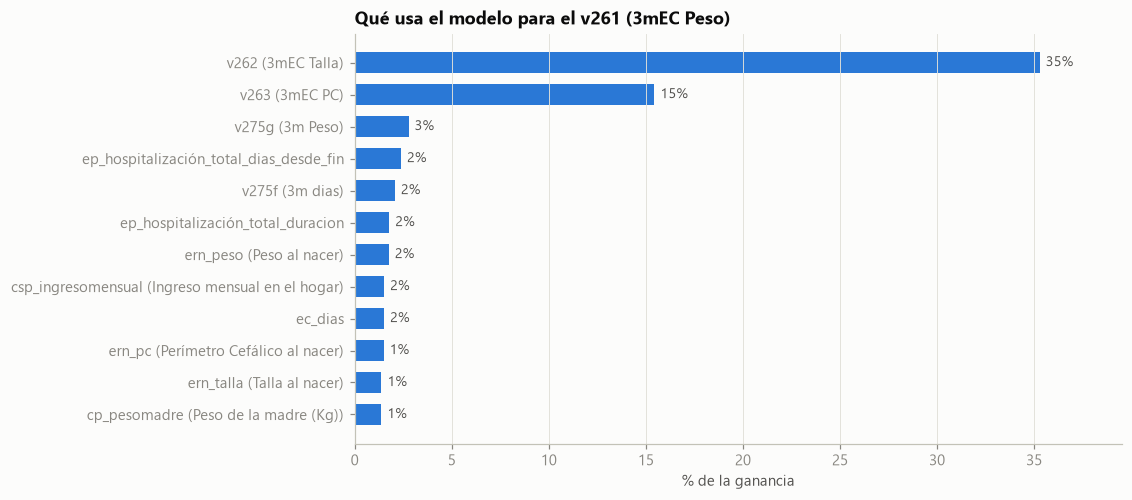

**Qué vemos.** La columna `pct_del_rango` dice qué tanto achica el contexto el rango esperado: para la mediana de las variables, la escala con contexto es el **52%** de la escala de la variable sola. Entre más chico, más finos son los errores que la capa 2 puede ver y que la capa 1 deja pasar. Las variables donde el contexto casi no ayuda (cerca de 100%) son las que no dependen del resto, y ahí la capa 2 agrega poco.

In [6]:
tab = modelo.tabla_capa2().join(modelo.estrechez(res)[['pct_del_rango']])
tab['alertas por 1.000'] = 1000 * d.groupby('variable').alerta2.mean().reindex(tab.index)
tab.index = [nombre(v) for v in tab.index]
display(tab.sort_values('n_entrenamiento', ascending=False).head(20))
peso3 = variable_de('peso', '3 m EC')
G.barh((100 * modelo.importancia(peso3)).rename(index=nombre), f'Qué usa el modelo para el {nombre(peso3)}', '% de la ganancia', fmt='{:.0f}%')
plt.show()
md(f'''**Qué vemos.** La columna `pct_del_rango` dice qué tanto achica el contexto el rango esperado: para la mediana de las variables, la escala con contexto es el **{pct(tab.pct_del_rango.median(), 0)}** de la escala de la variable sola. Entre más chico, más finos son los errores que la capa 2 puede ver y que la capa 1 deja pasar. Las variables donde el contexto casi no ayuda (cerca de 100%) son las que no dependen del resto, y ahí la capa 2 agrega poco.''')

## 6. Capa 3: trayectorias

Las variables que comparten concepto se encadenan por edad. Revisamos:

- que el dato caiga en la **ventana de su etapa** (en edad corregida desde las 40 semanas);
- que la **edad anotada coincida con la fecha** (14 días de tolerancia);
- que las etapas no estén **en desorden**;
- que la talla y el perímetro **no bajen** más de 1 cm;
- que el **cambio entre dos visitas** sea razonable para el tiempo que pasó, frente a los demás niños en esa misma transición.

Cuando un par de visitas sale raro, la culpa es del dato que comparte dos pares raros; si no hay cómo saberlo, se marcan los dos.

In [7]:
a3 = d[d.alerta3]
tabla3 = a3.assign(concepto=a3.concepto.fillna('(sin concepto)')).groupby(['motivo3', 'concepto']).size().unstack(fill_value=0)
display(tabla3)
md(f'''**Qué vemos.** {fmt(len(a3))} alertas de trayectoria en la prueba ({dec(1000 * len(a3) / d.tipo.eq('numeric').sum())} por cada 1.000 datos numéricos). La más común es **{a3.motivo3.value_counts().index[0] if len(a3) else '-'}**.''')

concepto,(sin concepto),perimetro_cefalico,peso,talla
motivo3,,,,
cambio atípico para el tiempo transcurrido,0,390,1091,458
disminuye y no debería,0,104,0,92
etapas en desorden,0,19,370,80
fuera de la ventana de la etapa,2189,357,410,400


**Qué vemos.** 5.960 alertas de trayectoria en la prueba (6,8 por cada 1.000 datos numéricos). La más común es **fuera de la ventana de la etapa**.

## 7. Capa 4: grupo y tiempo

Aquí sí usamos toda la historia, porque la pregunta es si algo cambió frente al pasado. Cada trimestre se compara con la mediana de los 8 trimestres anteriores, con tres señales. Antes esto se hacía por sede; como la base ya no la trae, ahora se compara todo el programa contra sí mismo. Un cambio en una sola sede se diluye en el total y se ve más tarde o no se ve.

- **residuo del contexto:** la mediana del residuo de la capa 2 se mueve de golpe, o poco a poco de forma sostenida (CUSUM);
- **datos faltantes:** cambia la proporción de visitas sin esa variable (un código especial cuenta como faltante);
- **redondeo:** cambia la proporción de valores terminados en 0.

Un nivel distinto pero estable no alerta: solo los cambios frente al propio pasado.

grupo,todo el programa
senal,
datos faltantes,287
redondeo,316
residuo del contexto,157


,grupo,periodo,variable,senal,valor,referencia,estadistico
0,todo el programa,2022Q4,v216 (Edad post natal a las 40 semanas EG (días)),datos faltantes,"0,00",1,"-306,00"
1,todo el programa,2022Q4,v220 (Perímetro C. a 40 sem),datos faltantes,"0,00",1,"-305,67"
2,todo el programa,2022Q3,v220 (Perímetro C. a 40 sem),datos faltantes,0,1,"-291,63"
3,todo el programa,2022Q3,v216 (Edad post natal a las 40 semanas EG (días)),datos faltantes,0,1,"-291,63"
4,todo el programa,2022Q2,v216 (Edad post natal a las 40 semanas EG (días)),datos faltantes,0,1,"-290,59"
5,todo el programa,2022Q2,v220 (Perímetro C. a 40 sem),datos faltantes,"0,00",1,"-290,25"
6,todo el programa,2022Q1,hd_numtrassanguineas (Numero de transfusiones ...,datos faltantes,"0,84",0,"255,82"
7,todo el programa,2022Q4,hd_numtrassanguineas (Numero de transfusiones ...,datos faltantes,"0,75","0,00","246,81"
8,todo el programa,2023Q4,v344c (6m Edad corregida de aplicación del test),redondeo,"0,02",1,"-244,18"
9,todo el programa,2022Q3,hd_numtrassanguineas (Numero de transfusiones ...,datos faltantes,"0,77",0,"243,40"


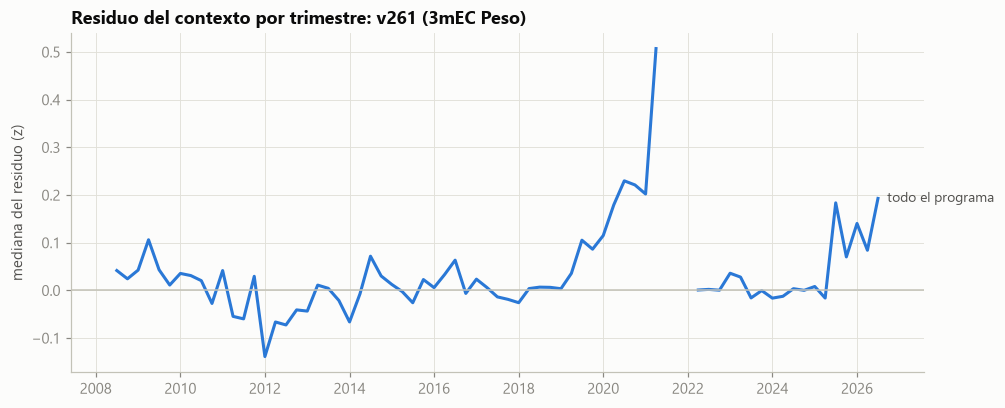

**Qué vemos.** Puntuar toda la historia tomó 3,3 minutos y deja **760 alarmas de grupo**. Cada una es una variable en un trimestre, no un niño, así que se pueden mirar con la Fundación sin exponer a nadie. 108 alarmas de redondeo caen entre finales de 2021 y 2023: si son el cambio de sistema que ya conocíamos, es una señal de la capa 4 y no algo que el modelo deba aprender como normal.

In [8]:
t0 = time.time()
res_total = modelo.puntuar(sev)
g = res_total.grupo
redondeo_2022 = int(((g.senal == 'redondeo') & g.periodo.between('2021-10-01', '2023-12-31')).sum())
display(g.groupby(['senal', 'grupo']).size().unstack(fill_value=0) if len(g) else 'Sin alarmas')
if len(g):
    vista = g.assign(variable=g.variable.map(nombre), periodo=g.periodo.dt.to_period('Q').astype(str))
    display(vista.reindex(vista.estadistico.abs().sort_values(ascending=False).index).head(20).reset_index(drop=True))
z = res_total.datos[res_total.datos.variable == peso3].dropna(subset=['z2', 't'])
serie = (z.assign(periodo=z.t.dt.to_period('Q').dt.start_time).groupby(['grupo', 'periodo']).z2
         .agg(['median', 'size']).reset_index().query('size >= 30'))
G.lines_by_group(serie, 'periodo', 'median', 'grupo', f'Residuo del contexto por trimestre: {nombre(peso3)}',
                 'mediana del residuo (z)', label='{}', baseline=0)
plt.show()
md(f'''**Qué vemos.** Puntuar toda la historia tomó {dec((time.time() - t0) / 60)} minutos y deja **{fmt(len(g))} alarmas de grupo**. Cada una es una variable en un trimestre, no un niño, así que se pueden mirar con la Fundación sin exponer a nadie. {fmt(redondeo_2022)} alarmas de redondeo caen entre finales de 2021 y 2023: si son el cambio de sistema que ya conocíamos, es una señal de la capa 4 y no algo que el modelo deba aprender como normal.''')

### ¿Cuánto tarda en ver una báscula que se descalibra?

Repetimos la prueba de la sección 8 del otro notebook, ahora con el modelo completo: a partir de una fecha, la báscula empieza a sumar un sesgo al peso de los 3 meses, y miramos cuántos trimestres tarda en saltar la alarma. Los sesgos van en múltiplos de la escala que la capa 2 espera para ese peso.

In [9]:
dz = res_total.datos[res_total.datos.variable == peso3].dropna(subset=['escala2', 't'])
grupo_mayor = dz.grupo.value_counts().index[0]
desde = dz[dz.grupo == grupo_mayor].t.quantile(0.6).to_period('Q').start_time
escala = float(dz.escala2.median())
# only what the layer-4 baseline needs: that group's children with this weight from 2.5 years before the change on
vecinos = dz[(dz.grupo == grupo_mayor) & (dz.t >= desde - pd.DateOffset(months=30))].sujeto.unique()
sub = sev.subconjunto(vecinos)
filas = []
for k in (0, 0.5, 1, 2):
    sesgo = round(k * escala)
    r = modelo.puntuar(MA.inyectar_sesgo(sub, peso3, grupo_mayor, desde, sesgo) if sesgo else sub).grupo
    hit = r[(r.variable == peso3) & (r.senal == 'residuo del contexto') & (r.periodo >= desde)]
    primero = hit.periodo.min()
    filas.append(dict(sesgo=sesgo, alarmas_desde_el_cambio=len(hit),
                      trimestres_hasta_alarma=np.nan if pd.isna(primero) else
                      (primero.to_period('Q') - desde.to_period('Q')).n))
deteccion = pd.DataFrame(filas).set_index('sesgo')
display(deteccion)
una = deteccion.trimestres_hasta_alarma.iloc[2]
md(f'''**Qué vemos.** El sesgo empieza en {desde:%m/%Y} ({grupo_txt(grupo_mayor)}). Sin sesgo hay {fmt(deteccion.alarmas_desde_el_cambio.iloc[0])} alarmas en ese periodo (esas serían falsas). Con un sesgo de una escala (unos {fmt(escala)} en la unidad de la variable) ''' + (('la alarma salta en el mismo trimestre.' if una == 0 else f'la alarma salta a los {una:.0f} trimestres.') if pd.notna(una) else 'la alarma no salta: ese sesgo queda por debajo de lo que la capa 4 puede ver.'))

,alarmas_desde_el_cambio,trimestres_hasta_alarma
sesgo,,
0,3,4
203,7,0
407,6,0
814,7,0


**Qué vemos.** El sesgo empieza en 07/2019 (todo el programa). Sin sesgo hay 3 alarmas en ese periodo (esas serían falsas). Con un sesgo de una escala (unos 407 en la unidad de la variable) la alarma salta en el mismo trimestre.

## 8. Lo que encontró en toda la base

Ahora el modelo revisa toda la historia, como lo haría el primer día de uso. Cada dato con alguna alerta entra una sola vez a la cola de revisión, aunque lo marquen varias capas. Primero van los que marcan más capas y, entre ellos, los que más se pasan de su umbral. Aquí solo mostramos cuántos son y dónde están: la lista por niño la arma `python -m anomalias revisar` en `salidas/revision_de_datos/`.

,datos,sujetos
capas,,
2,37602,25602
3,32563,10212
1,19924,11907
"1, 2",8768,7547
"1, 3",2888,2117
"1, 2, 3",2217,2022
"2, 3",1351,1271


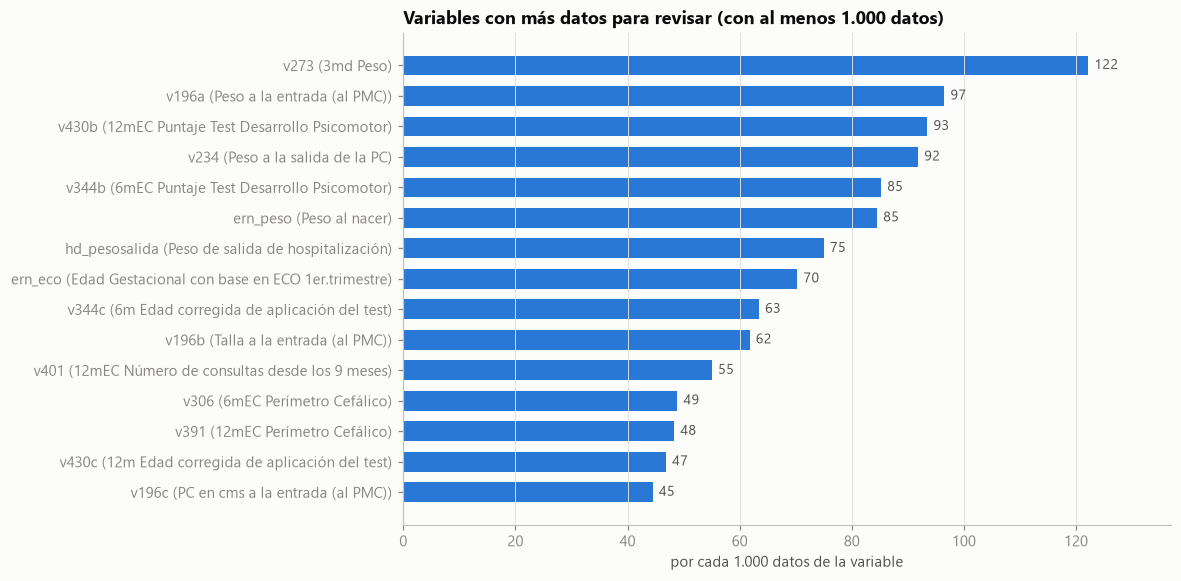

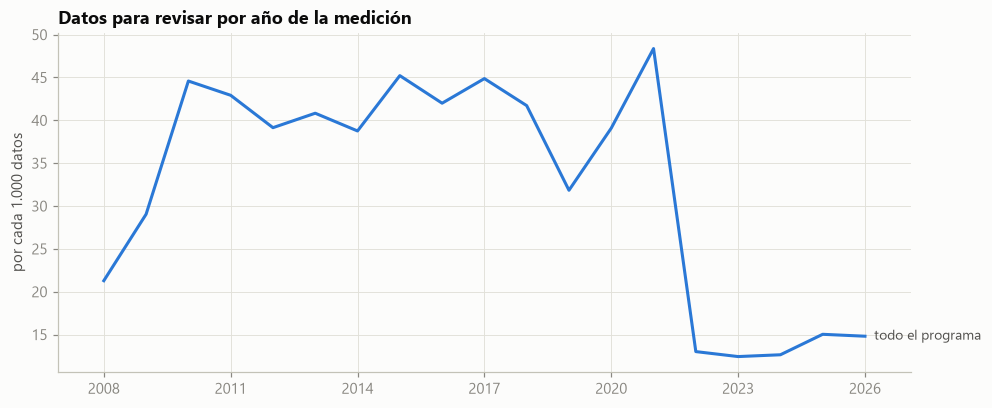

**Qué vemos.** En toda la base hay **105.313 datos para revisar** (19,4 por cada 1.000 datos numéricos), de 38.466 niños. 15.224 los marcan dos capas o más: esos van primero en la cola. Entre las variables con al menos 1.000 datos, la que más alerta es **v273 (3md Peso)**, con 122,2 por cada 1.000 de sus datos. Antes de 2022 la mediana es de 41,3 datos para revisar por cada 1.000 al año, y desde 2022, de 13,0: el sistema nuevo deja muchos menos datos raros. Por eso el modelo mide antes y después de 2022 por separado. Revisar toda la historia de una vez no es realista; en el uso diario la cola es solo de lo que entró desde la revisión anterior.

In [10]:
cola = OP.cola_revision(res_total, esq, modelo.cfg)
dt = res_total.datos
num = dt[dt.tipo == 'numeric']
display(OP.resumen_cola(cola))
n_var = num.groupby('variable').size()
por_var = 1000 * cola.groupby('variable').size().reindex(n_var.index, fill_value=0) / n_var
top = por_var[n_var >= 1000].sort_values(ascending=False).head(15)  # a rate over a few dozen data says little
G.barh(top.rename(index=nombre), 'Variables con más datos para revisar (con al menos 1.000 datos)', 'por cada 1.000 datos de la variable', fmt='{:.0f}')
plt.show()
anual = (num.assign(alerta=num.alerta1 | num.alerta2 | num.alerta3, anio=num.t.dt.year)
         .groupby(['grupo', 'anio']).alerta.agg(['mean', 'size']).reset_index().query('size >= 500'))
anual['por_1000'] = 1000 * anual['mean']
corte_q = pd.Timestamp(sev.quiebres.fecha.min()).year
antes_q = anual[anual.anio < corte_q].groupby('anio').por_1000.mean().median()
desde_q = anual[anual.anio >= corte_q].groupby('anio').por_1000.mean().median()
G.lines_by_group(anual, 'anio', 'por_1000', 'grupo', 'Datos para revisar por año de la medición', 'por cada 1.000 datos', label='{}')
plt.show()
md(f'''**Qué vemos.** En toda la base hay **{fmt(len(cola))} datos para revisar** ({dec(1000 * len(cola) / len(num))} por cada 1.000 datos numéricos), de {fmt(cola.sujeto.nunique())} niños. {fmt((cola.n_capas >= 2).sum())} los marcan dos capas o más: esos van primero en la cola. Entre las variables con al menos 1.000 datos, la que más alerta es **{nombre(top.index[0])}**, con {dec(top.iloc[0])} por cada 1.000 de sus datos. Antes de {corte_q} la mediana es de {dec(antes_q)} datos para revisar por cada 1.000 al año, y desde {corte_q}, de {dec(desde_q)}: el sistema nuevo deja muchos menos datos raros. Por eso el modelo mide antes y después de 2022 por separado. Revisar toda la historia de una vez no es realista; en el uso diario la cola es solo de lo que entró desde la revisión anterior.''')

## 9. ¿Funciona? Errores inyectados

Metemos errores de tipo conocido en datos limpios de la prueba, más o menos el 2% de los datos por ronda, en tres rondas:

| Error | Qué simula |
|---|---|
| unidad | multiplicar o dividir por 10 (o pasar gramos a kilos) |
| código | un -1, 999 o 9999 donde no van |
| dígitos | dos dígitos al revés |
| desvío de 3 DE | un valor plausible para la variable, pero corrido 3 desviaciones |
| valor de otro sujeto | el dato de otro niño en la misma variable |
| etapas intercambiadas | los valores de dos visitas cambiados de lugar |

Las falsas alertas se miden en la prueba **sin** errores inyectados, para que un error metido no contamine a sus vecinos. Son un techo: los datos "limpios" todavía tienen errores reales que nadie ha marcado.

Al lado va lo que ya hace la base hoy: marcar lo que queda fuera del **rango del diccionario**. Es la línea base que el modelo tiene que superar.

Al final está la **curva de `alpha`**: con los mismos puntajes, cuántos errores se encontrarían y cuántas falsas alarmas habría en datos limpios si la capa 2 fuera más o menos exigente (`alpha` es la tasa de falsas alarmas que se le pide en datos limpios). Es una propiedad del modelo: `alpha` se elige con la precisión que midan los expertos, no con cuántos datos alcance a revisar alguien. Cuántos se muestran, y en qué orden, lo decide la app.

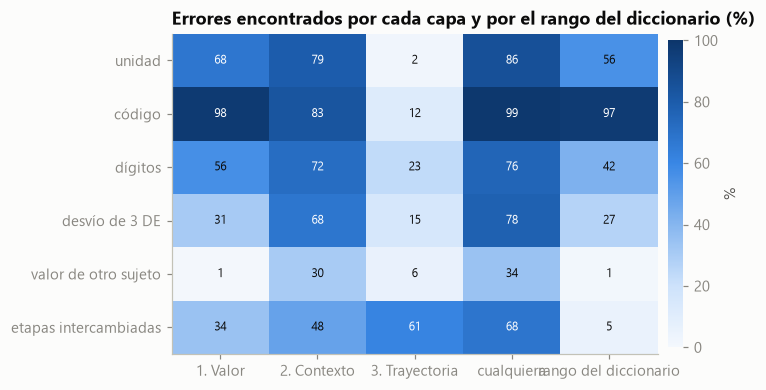

,errores,1. Valor,2. Contexto,3. Trayectoria,cualquiera,rango del diccionario
tipo,,,,,,
unidad,4901,"67,56","79,47","1,98","85,76","55,83"
código,7974,"97,58","83,43","11,61","98,77","97,24"
dígitos,2335,"56,40","71,86","23,30","75,55","41,93"
desvío de 3 DE,5039,"30,68","67,75","15,38","77,69","26,65"
valor de otro sujeto,4774,"0,75","30,29","5,84","34,33","0,92"
etapas intercambiadas,7974,"34,00","48,22","61,16","68,30","5,44"


,1. Valor,2. Contexto,3. Trayectoria,cualquiera,rango del diccionario
alertas por 1.000 datos limpios,"4,40","8,92","7,17","18,81","14,71"


**Qué vemos.** Juntando las capas, el modelo encuentra entre el **34%** y el **99%** de los errores según el tipo, con **18,8 alertas por cada 1.000 datos limpios**. Lo más difícil es **valor de otro sujeto**: es un valor que podría ser de cualquier niño, y solo se nota cuando choca con el resto de su información. En los desvíos de 3 DE la capa 1 encuentra el 31% y la capa 2 el 68%: esa diferencia es lo que aporta el contexto. El rango del diccionario, que es lo que hay hoy, encuentra entre el 1% y el 97%, con 14,7 alertas por cada 1.000 datos limpios. (2,3 minutos.)

In [11]:
POR_QUE = {
    'valor de otro sujeto': ': es un valor que podría ser de cualquier niño, y solo se nota cuando choca con el resto de su información',
    'dígitos': ': si los dígitos cambiados quedan cerca, el valor sigue siendo plausible',
    'etapas intercambiadas': ': cuando dos visitas están cerca en el tiempo, cambiarlas casi no se nota',
}
t0 = time.time()
ev = MA.evaluar(modelo, te, rondas=3, base=res)
recall, falsas = ev.recall, ev.falsas
capas = ['1. Valor', '2. Contexto', '3. Trayectoria', 'cualquiera', MA.BASE_COMPARACION]
G.heatmap(recall[capas], 'Errores encontrados por cada capa y por el rango del diccionario (%)', '%', vmin=0, vmax=100)
plt.show()
display(recall)
display(falsas)
md(f'''**Qué vemos.** Juntando las capas, el modelo encuentra entre el **{pct(recall.cualquiera.min(), 0)}** y el **{pct(recall.cualquiera.max(), 0)}** de los errores según el tipo, con **{dec(falsas.cualquiera.iloc[0])} alertas por cada 1.000 datos limpios**. Lo más difícil es **{recall.cualquiera.idxmin()}**{POR_QUE.get(recall.cualquiera.idxmin(), '')}. En los desvíos de 3 DE la capa 1 encuentra el {pct(recall.loc['desvío de 3 DE', '1. Valor'], 0)} y la capa 2 el {pct(recall.loc['desvío de 3 DE', '2. Contexto'], 0)}: esa diferencia es lo que aporta el contexto. El rango del diccionario, que es lo que hay hoy, encuentra entre el {pct(recall[MA.BASE_COMPARACION].min(), 0)} y el {pct(recall[MA.BASE_COMPARACION].max(), 0)}, con {dec(falsas[MA.BASE_COMPARACION].iloc[0])} alertas por cada 1.000 datos limpios. ({dec((time.time() - t0) / 60)} minutos.)''')

,capa 2 por 1.000 limpios,total por 1.000 limpios,errores encontrados (%)
alpha,,,
"0,00","4,99","15,24","72,68"
"0,00","5,94","16,06","73,59"
"0,01","8,92","18,81","75,29"
"0,01","13,87","23,47","77,17"
"0,02","23,74","32,98","79,82"


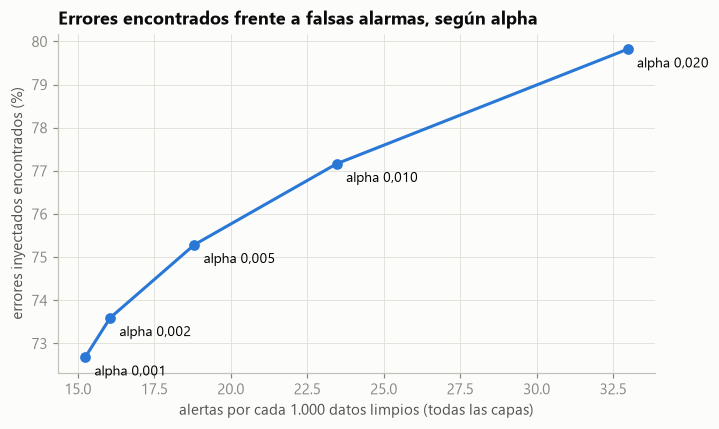

**Qué vemos.** Con el umbral actual (alpha 0,005) salen 18,8 alertas por cada 1.000 datos limpios y se encuentra el 75% de los errores. Con alpha 0,001 serían 15,2 alertas y el 73% de los errores. La capa 2 alerta más que su meta en datos "limpios" (8,9 frente a 5,0) porque la calibración descarta su peor 1% como suciedad y aquí esos casos cuentan como falsas alertas: parte de ellas son errores reales. Cuál es cuál solo lo dice la revisión de expertos (sección 11).

In [12]:
curva = ev.curva
display(curva)
eje = curva.reset_index()
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(eje['total por 1.000 limpios'], eje['errores encontrados (%)'], marker='o', color=G.SERIES[0])
for r in eje.itertuples():
    ax.annotate(f'alpha {dec(r.alpha, 3)}', (r[3], r[4]), textcoords='offset points', xytext=(6, -12), fontsize=9)
ax.set_xlabel('alertas por cada 1.000 datos limpios (todas las capas)')
ax.set_ylabel('errores inyectados encontrados (%)')
ax.set_title('Errores encontrados frente a falsas alarmas, según alpha')
plt.show()
actual, minimo = curva.loc[modelo.cfg.alpha], curva.iloc[0]
md(f'''**Qué vemos.** Con el umbral actual (alpha {dec(modelo.cfg.alpha, 3)}) salen {dec(actual['total por 1.000 limpios'])} alertas por cada 1.000 datos limpios y se encuentra el {pct(actual['errores encontrados (%)'], 0)} de los errores. Con alpha {dec(curva.index[0], 3)} serían {dec(minimo['total por 1.000 limpios'])} alertas y el {pct(minimo['errores encontrados (%)'], 0)} de los errores. La capa 2 alerta más que su meta en datos "limpios" ({dec(actual['capa 2 por 1.000 limpios'])} frente a {dec(1000 * modelo.cfg.alpha)}) porque la calibración descarta su peor 1% como suciedad y aquí esos casos cuentan como falsas alertas: parte de ellas son errores reales. Cuál es cuál solo lo dice la revisión de expertos (sección 11).''')

## 10. Una variable nueva, sin tocar código

Hacemos de cuenta que una variable de talla es nueva: le quitamos su modelo y su referencia, como si los expertos la acabaran de agregar al esquema.

- La capa 1 la revisa desde el primer dato, con su propia mediana y MAD.
- La capa 3 la encadena con las demás tallas porque trae concepto.
- La capa 2 espera a que se entrene su modelo, y ese entrenamiento es solo de ella.

In [13]:
etapas_talla = esq[(esq.concepto == 'talla') & esq.ventana & esq.etapa.notna()].etapa
nueva = variable_de('talla', max(etapas_talla, key=lambda e: orden[e]))
m2 = modelo.sin_variable(nueva)
antes = m2.puntuar(te).datos.query('variable == @nueva')
t0 = time.time()
m2.ajustar(tr, ca, solo_nuevas=True)
segundos = time.time() - t0
despues = m2.puntuar(te).datos.query('variable == @nueva')
comparacion = pd.DataFrame({
    'recién agregada': [antes.z1.notna().mean() * 100, antes.alerta1.sum(), antes.alerta3.sum(), antes.z2.notna().mean() * 100],
    'con su modelo': [despues.z1.notna().mean() * 100, despues.alerta1.sum(), despues.alerta3.sum(), despues.z2.notna().mean() * 100],
}, index=['% de datos con puntaje de capa 1', 'alertas capa 1', 'alertas capa 3', '% de datos con puntaje de capa 2'])
display(comparacion)
md(f'''**Qué vemos.** Con **{nombre(nueva)}** recién agregada, las capas 1 y 3 ya funcionan y la 2 todavía no. Entrenar solo su modelo tomó {segundos:.0f} s y no cambió ninguno de los otros {len(modelo.capa2) - 1}. Nada de esto requirió cambiar código: es una fila en el esquema.''')

,recién agregada,con su modelo
% de datos con puntaje de capa 1,100,100
alertas capa 1,10,10
alertas capa 3,153,153
% de datos con puntaje de capa 2,0,100


**Qué vemos.** Con **v390 (12mEC Talla)** recién agregada, las capas 1 y 3 ya funcionan y la 2 todavía no. Entrenar solo su modelo tomó 45 s y no cambió ninguno de los otros 131. Nada de esto requirió cambiar código: es una fila en el esquema.

## 11. Uso diario

El notebook valida; el trabajo de todos los días lo hace `python -m anomalias`, desde la terminal y con `KMC_PW` definida:

| Orden | Qué hace | Qué deja |
|---|---|---|
| `python -m anomalias entrenar` | Repite esta validación, entrena el modelo con **todos** los datos y lo guarda con su ficha (de qué datos aprendió, cómo le fue en la validación, con qué parámetros) | `interno/anomalias/modelos/<versión>/` |
| `python -m anomalias revisar` | Puntúa la base y arma la cola de lo que entró desde la revisión anterior (la primera vez, toda la historia). Compara las alertas con las de la validación y avisa si una capa se dispara | `salidas/revision_de_datos/<fecha>.xlsx`, con instrucciones, los datos por revisar, los cambios por grupo y los datos no usados |
| `python -m retroalimentacion expertos` | Archivo ciego para los expertos: alertas de cada capa mezcladas con datos sin alerta, sin decir cuál es cuál. Abre con instrucciones y la respuesta ("¿Es un error?") solo acepta Sí, No o No sé | `entradas/retroalimentacion/expertos_<versión>.xlsx` |
| `python -m retroalimentacion precision` | Con el archivo ya respondido en `entradas/retroalimentacion/`, qué porcentaje de las alertas de cada capa son errores de verdad, y cuántos errores se escapan en los datos sin alerta | una tabla en pantalla |
| `python -m anomalias modelos` | Los modelos guardados, el más reciente primero | una tabla en pantalla |

`python pipeline.py` corre la corrida completa en orden (anomalías y luego alertas clínicas). Con otra fuente que entregue las seis tablas SEVARTI en Parquet, en lugar de la base se le pasa la carpeta: `python -m anomalias --sevarti CARPETA revisar`. Los parámetros se cambian sin tocar código con `entrenar --config archivo.json` (por ejemplo, `{"alpha": 0.002}` para que la capa 2 sea más exigente).

La cola y el archivo de expertos tienen datos por niño, con el `paciente_id` de la base: se quedan en `salidas/`, `entradas/retroalimentacion/` e `interno/` y no se comparten fuera del equipo que revisa.

In [14]:
guardados = OP.fichas(PROYECTO.modelos_anomalias)
if len(guardados):
    display(guardados.drop(columns='carpeta'))
else:
    md('Todavía no hay modelos guardados: el primero sale de `python -m anomalias entrenar`.')

,version,entrenado,corte_datos,sujetos,modelos_capa2,alertas_por_1000
0,98aaa133d1,2026-10-19T13:40:37,2026-07-24,62043,132,"21,29"


## 12. Qué sigue

- **Revisión con expertos.** El archivo sale de `python -m retroalimentacion expertos`; falta que lo respondan. Sin eso no sabemos cuántas de las alertas en datos "limpios" son errores de verdad, y es lo que decide si se sube o se baja `alpha`.
- **Decisiones abiertas.** Por ahora el modelo queda como está. Las que lo tocan son tres: las ventanas de cada visita (hoy con márgenes nuestros), volver a usar la sede y la fecha de parto (hoy la capa 4 vigila el programa completo como un solo grupo) y los pesos extra de cada visita (`v273`, `v275g`, `v317g`, `v360g`, `v402g`), cuyo campo de "días" no es la edad del niño (su mediana va de 27 a 140 días en visitas de 3 a 12 meses): se ubican en la fecha de la visita y no se encadenan con la trayectoria.
- **Lo que pidió la Fundación** ya está: las estancias salen de `hd_diasurn` y `hd_totaldiashospital`, la edad corregida usa `EG_Semanas`, y el único cambio de sistema declarado es el de 2022 (sección 8); la capa 4 avisa de los demás.
- Las variables de posición canguro en casa entran solas, como filas del esquema, cuando la Fundación las cargue.

**Pruebas del código:** `python -m pytest pruebas` corre con datos simulados en un par de minutos. Los datos simulados existen solo para las pruebas: todo lo de este notebook es con la base real.